In [1]:
import numpy as np
import matplotlib.pyplot as plt
import provenance as prov, tools

bgs_smlim_wp DD: cat-309d7a8 cnt-43a1a50 (2026-11-16 11:15, calculation of 2pcf in BGS and ABacus with new pipeline)
bgs_smlim_wp DR: cat-309d7a8 cnt-43a1a50 (2026-11-16 11:15, calculation of 2pcf in BGS and ABacus with new pipeline)
maps_wp DD: cat-f0d43de cnt-43a1a50 (2026-11-16 11:15, calculation of 2pcf in BGS and ABacus with new pipeline)
maps_wp DR: cat-f0d43de cnt-43a1a50 (2026-11-16 11:15, calculation of 2pcf in BGS and ABacus with new pipeline)


DirtyTreeError: uncommitted changes in:
  BGS_Abacus_clustering.ipynb (code cells changed)
commit them before running, so outputs can be tagged with a commit hash.

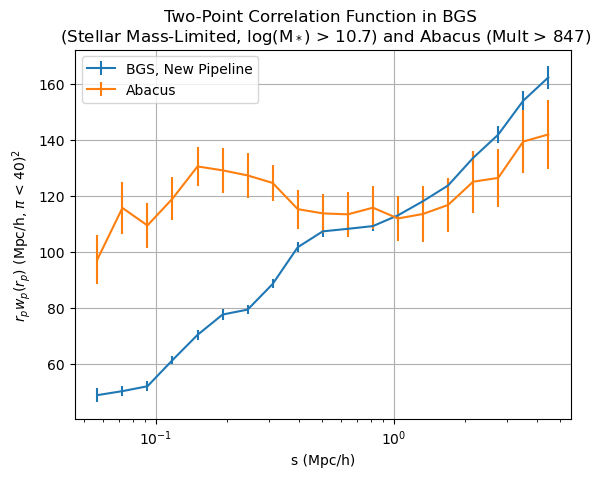

In [21]:
dd = prov.count_files("bgs_smlim_wp", "DD")      # matches the current code by default
dr = prov.count_files("bgs_smlim_wp", "DR")[0]
r, rwp, err = tools.DavisPeebles2PCFJackknifeCoadd(dd, dr, statistic="wp", paths=True)
plt.errorbar(r, rwp, yerr=err, label="BGS, New Pipeline")


ddab = prov.count_files("maps_wp", "DD")      # matches the current code by default
drab = prov.count_files("maps_wp", "DR")[0]
r, rwp, err = tools.DavisPeebles2PCFJackknifeCoadd(ddab, drab, statistic="wp", paths=True)
plt.errorbar(r, rwp, yerr=err, label="Abacus")
plt.grid(True)

'''
s, s2xi0, err = tools.DavisPeebles2PCFJackknifeCoadd(["BGSxquantile_bgsbright_SMlimited_s"], "BGSxquantile_bgsxran_s", statistic='xi0')
#the "bright" label is a misnomer
plt.errorbar(s,s2xi0,yerr = err,color='red',label="BGS, Old Calculation")
'''
plt.xscale('log')
plt.xlabel("s (Mpc/h)")
plt.ylabel(r"$r_pw_p(r_p)$ (Mpc/h), $\pi < 40$ Mpc/h")
plt.title("Two-Point Correlation Function in BGS \n (Stellar Mass-Limited, log(M$_*$) > 10.7) and Abacus (Mult > 847)")
plt.legend()

provname = prov.plot_name("rppi_bgs_vs_maps", dd + [dr] + ddab + [drab], "BGS_Abacus_clustering.ipynb")
print(provname)
plt.savefig(provname)

